In [1]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('animation', html='html5')

In [2]:
import pandas as pd

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GroupShuffleSplit

from tensorflow.keras import Sequential, callbacks, layers


spotify = pd.read_csv('../datasets/dl-course-data/spotify.csv')

X = spotify.copy().dropna()
y = X.pop('track_popularity')

artists = X['track_artist']
features_num = ['danceability', 'energy', 'key', 'loudness', 'mode',
                'speechiness', 'acousticness', 'instrumentalness',
                'liveness', 'valence', 'tempo', 'duration_ms']
features_cat = ['playlist_genre']

preprocessor = make_column_transformer(
    (StandardScaler(), features_num),
    (OneHotEncoder(), features_cat),
)

def group_split(X, y, group, train_size=0.75):
    splitter = GroupShuffleSplit(train_size=train_size)
    train, test = next(splitter.split(X, y, groups=group))
    return (X.iloc[train], X.iloc[test], y.iloc[train], y.iloc[test])

X_train, X_valid, y_train, y_valid = group_split(X, y, artists)

X_train = preprocessor.fit_transform(X_train)
y_train = y_train / 100

X_valid = preprocessor.transform(X_valid)
y_valid = y_valid / 100

INPUT_SHAPE = [X_train.shape[1]]
print(f"Input shape: {INPUT_SHAPE}")

2025-01-23 11:22:18.086100: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-23 11:22:18.090100: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-23 11:22:18.102703: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737631338.122719   39676 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737631338.129164   39676 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-23 11:22:18.152611: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

Input shape: [18]


In [3]:
HIDDEN_SHAPE_1, HIDDEN_SHAPE_2, OUTPUT_SHAPE = 128, 64, 1
DROPOUT_RATE = 0.3
ReLU = "relu"


# Add two 30% dropout layers, one after 128 and one after 64
model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Dense(HIDDEN_SHAPE_1, activation=ReLU),
    layers.Dropout(DROPOUT_RATE),
    layers.Dense(HIDDEN_SHAPE_2, activation=ReLU),
    layers.Dropout(DROPOUT_RATE),
    layers.Dense(OUTPUT_SHAPE)
])

2025-01-23 11:22:20.618128: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Minimum Validation Loss: 0.1911


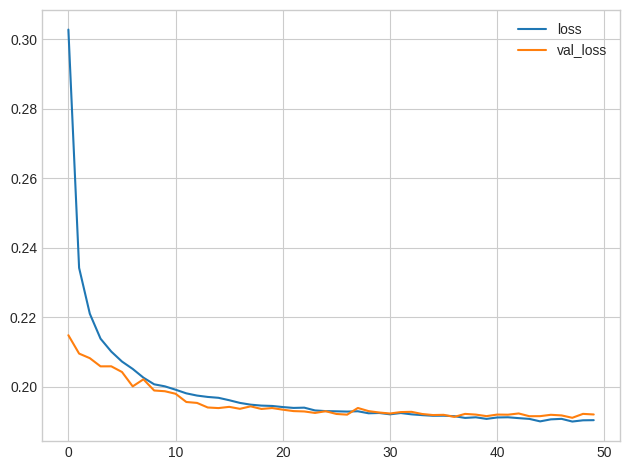

In [4]:
model.compile(
    optimizer='adam',
    loss='mae',
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    verbose=0,
)

history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()
print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}")

In [5]:
from IPython.display import display, Markdown

content = f"""
**Q**: **In the overfitting/undefitting exercice, this model tended to overfit the data around epoch 5. Did adding 
dropout seem to help prevent overfitting this time?**<br>
**A**: The validation loss remains near a constant minimum even though the training loss continues to decrease. 
Adding dropout did prevent overfitting this time. Moreover, by making it harder for the network to 
fit spurious patterns, dropout may have encouraged the network to seek out more of the true patterns, possibly 
improving the validation loss some as well.
"""

display(Markdown(content))


**Q**: **In the overfitting/undefitting exercice, this model tended to overfit the data around epoch 5. Did adding 
dropout seem to help prevent overfitting this time?**<br>
**A**: The validation loss remains near a constant minimum even though the training loss continues to decrease. 
Adding dropout did prevent overfitting this time. Moreover, by making it harder for the network to 
fit spurious patterns, dropout may have encouraged the network to seek out more of the true patterns, possibly 
improving the validation loss some as well.


In [6]:
import pandas as pd

concrete = pd.read_csv('../datasets/dl-course-data/concrete.csv')
df = concrete.copy()

df_train = df.sample(frac=0.7, random_state=0)
df_valid = df.drop(df_train.index)

X_train = df_train.drop('CompressiveStrength', axis=1)
y_train = df_train['CompressiveStrength']

X_valid = df_valid.drop('CompressiveStrength', axis=1)
y_valid = df_valid['CompressiveStrength']

INPUT_SHAPE = [X_train.shape[1]]

Minimum Validation Loss: nan


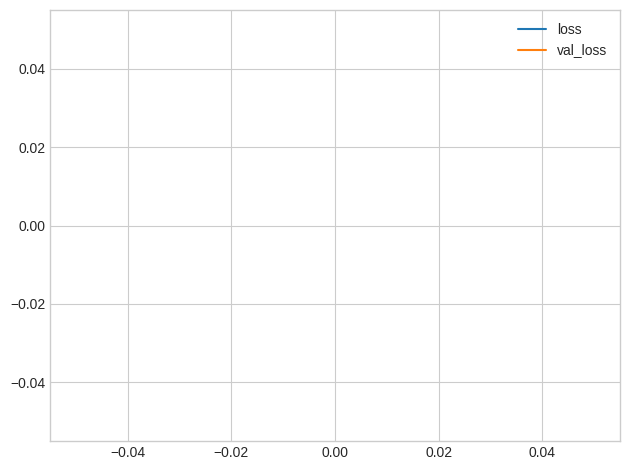

In [7]:
HIDDEN_SHAPE, OUTPUT_SHAPE = 512, 1
ReLU = "relu"
EPOCHS = 100

model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),    
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.Dense(OUTPUT_SHAPE),
])

model.compile(
    optimizer='sgd', # SGD is more sensitive to differences of scale
    loss='mae',
    metrics=['mae'],
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=64,
    epochs=EPOCHS,
    verbose=0,
)

history_df = pd.DataFrame(history.history)
history_df.loc[0:, ['loss', 'val_loss']].plot()
print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}")

In [8]:
content = f"""
Did you end up with a blank graph? *Trying to train this network on this dataset will usually fail.*
Even when it does converge (due to a lucky weight initialization), it tends to converge to a very large number.
"""
display(Markdown(content))


Did you end up with a blank graph? *Trying to train this network on this dataset will usually fail.*
Even when it does converge (due to a lucky weight initialization), it tends to converge to a very large number.


Minimum Validation Loss: 3.9263


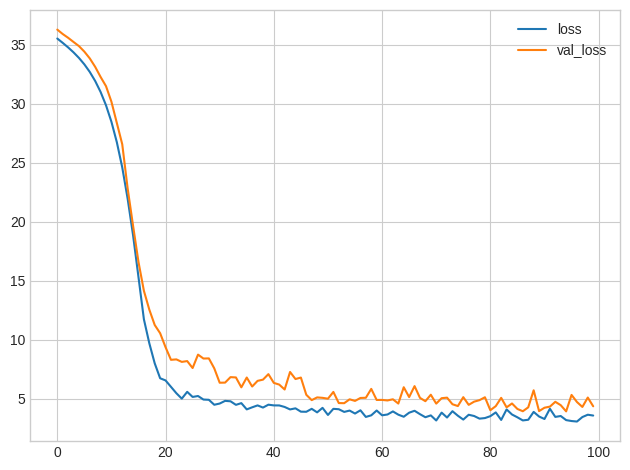

In [9]:
model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.BatchNormalization(),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.BatchNormalization(),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.BatchNormalization(),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.BatchNormalization(),
    layers.Dense(OUTPUT_SHAPE),
])

model.compile(
    optimizer='sgd',
    loss='mae',
    metrics=['mae'],
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=64,
    epochs=EPOCHS,
    verbose=0,
)

history_df = pd.DataFrame(history.history)
history_df.loc[0:, ['loss', 'val_loss']].plot()
print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}")

In [10]:
content = f"""
**Q**: **Did adding batch normalization help?**<br>
Adding batch normalization was a big improvement on the first attempt! By adaptively scaling the 
data as it passes through the network, batch normalization can let you train models on difficult 
datasets.
"""

display(Markdown(content))



**Q**: **Did adding batch normalization help?**<br>
Adding batch normalization was a big improvement on the first attempt! By adaptively scaling the 
data as it passes through the network, batch normalization can let you train models on difficult 
datasets.
